In [ ]:
%pip install ipykernel
%pip install opencv-python 
%pip install matplotlib
%pip install plotly nbformat

In [2]:
import cv2 as cv 
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm, colors

In [3]:
#TC001 
#Connect to the camera using OpenCV

camera_index = 0  # Change this to the appropriate index for your camera

cap = cv.VideoCapture(camera_index)

if not cap.isOpened():
    print("Error: Could not open camera.")

# Get camera properties
print("Frame Width:", cap.get(cv.CAP_PROP_FRAME_WIDTH))
print("Frame Height:", cap.get(cv.CAP_PROP_FRAME_HEIGHT))
print("FPS:", cap.get(cv.CAP_PROP_FPS))
print("Total FPS:", cap.get(cv.CAP_PROP_FRAME_COUNT)/cap.get(cv.CAP_PROP_FPS))

print(cap.get(cv.CAP_PROP_POS_FRAMES))  # Current frame position
print("Current Position (ms):", cap.get(cv.CAP_PROP_POS_MSEC))  # Current position in milliseconds


Frame Width: 640.0
Frame Height: 480.0
FPS: 30.0
Total FPS: -0.03333333333333333
0.0
Current Position (ms): 0.0


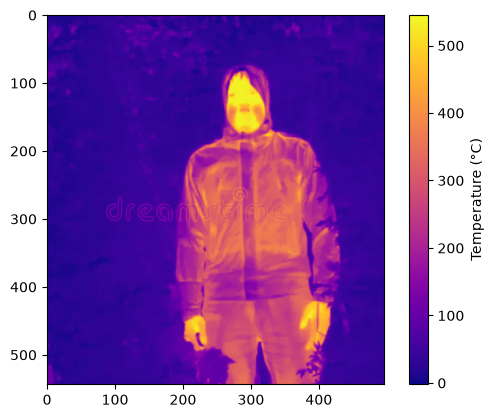

6.0 6.0 6.0


C:\Users\Aldrich\AppData\Local\Temp\ipykernel_12052\568926004.py:66: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.view_init(elev=15, azim=-55); ax2.legend()


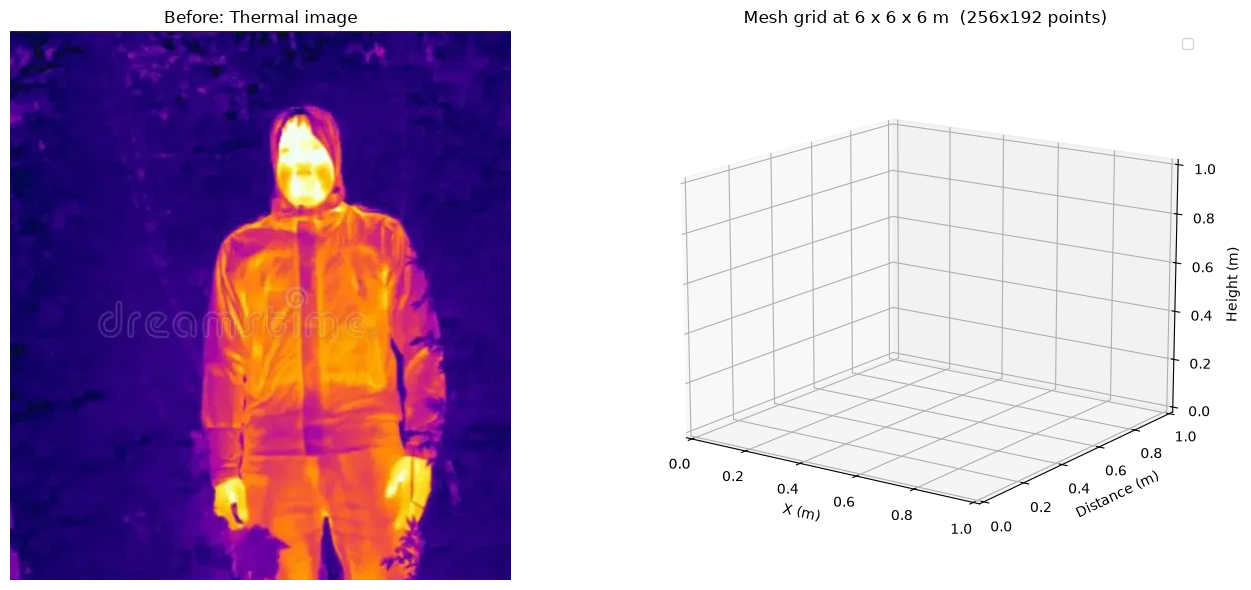

In [ ]:
#Define Width and Height image Capture
cam_width = 256
cam_height = 192

cap.set(cv.CAP_PROP_FRAME_WIDTH, cam_width)
cap.set(cv.CAP_PROP_FRAME_HEIGHT, cam_height)


#Config
cam_default_distance = 5.0 #5 meters 16 feet 

cam_min_temp = -20.0
cam_max_temp = 550.0 

cam_high_temp = 100.0 
cam_low_temp = 20.0

#Cam Width and Height
HFOV_DEG = 56.0
VFOV_DEG = 42.0

#Mesh Downsampling
mesh_downsample_factor = 1  # Downsample factor for the mesh grid
TEMP_RANGE = (cam_min_temp, cam_max_temp)  # Temperature range in Celsius
image_path = "thermal_image.png"  # Path to the thermal image file

#Image
img = cv.imread(image_path)


#image color bar
data = cv.cvtColor(img, cv.COLOR_BGR2GRAY).astype(np.float32)

#normalize the data to the temperature range
data = (data / 255.0) * (cam_high_temp - cam_low_temp) + cam_low_temp

fig, ax = plt.subplots()
im = ax.imshow(data, cmap='plasma')
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Temperature (°C)')
plt.show()


#Meshgrid generation
SIZE = 6.0   # metres per axis
N = 50       # points per axis (change as needed)

x = np.linspace(-SIZE / 2, SIZE / 2, N)
y = np.linspace(-SIZE / 2, SIZE / 2, N)
z = np.linspace(-SIZE / 2, SIZE / 2, N)

X, Y, Z = np.meshgrid(x, y, z, indexing="ij")   # each has shape (N, N, N)

print(X.max() - X.min(), Y.max() - Y.min(), Z.max() - Z.min())

# Display: left = image, right = mesh grid
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax1.set_title("Before: Thermal image")
ax1.axis("off")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")

ax2.set_xlabel("X (m)"); ax2.set_ylabel("Distance (m)"); ax2.set_zlabel("Height (m)")
ax2.set_title(f"Mesh grid at 6 x 6 x 6 m  ({cam_width}x{cam_height} points)")
ax2.view_init(elev=15, azim=-55); ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
#Send ESP
 
 
 
 
 